Step 1: Setup, Packages, and Cost Configuration


In [71]:
# ============================================================
# 1. SETUP AND CONFIGURATION  (corrected)
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.base import clone
from sklearn.model_selection import (StratifiedKFold, train_test_split,
                                     cross_val_predict, RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import log_loss, roc_auc_score

# In Colab, upload the two CSVs to the session storage (or mount Drive) first
TRAIN_PATH = "dataset_C_training.csv"
TEST_PATH = "dataset_C_testing.csv"
TARGET = "covid_vaccine"
ID_COL = "respondent_id"
RANDOM_STATE = 42
N_FOLDS = 5
N_SEARCH_ITER = 20

# Costs from the Dataset Information PDF
COST_MISSED_UNVACCINATED = 41_000  # predicted vaccinated (1) but actually not (0)
COST_WASTED_VACCINATED = 1_500     # predicted not vaccinated (0) but actually vaccinated (1)

sns.set_theme(style="whitegrid")

Step 2: Data Loading and Exploratory Data Analysis (EDA)

Train shape: (4756, 31) | Test shape: (4749, 30)
   respondent_id  covid_concern  covid_knowledge  behavioral_antiviral_meds  \
0              1            3.0              1.0                        0.0   
1              2            2.0              1.0                        0.0   
2              3            0.0              2.0                        0.0   
3              4            2.0              2.0                        0.0   
4              5            1.0              1.0                        0.0   

   behavioral_avoidance  behavioral_face_mask  behavioral_wash_hands  \
0                   1.0                   0.0                    1.0   
1                   1.0                   0.0                    1.0   
2                   0.0                   0.0                    0.0   
3                   1.0                   0.0                    1.0   
4                   1.0                   0.0                    0.0   

   behavioral_large_gatherings  behavioral_

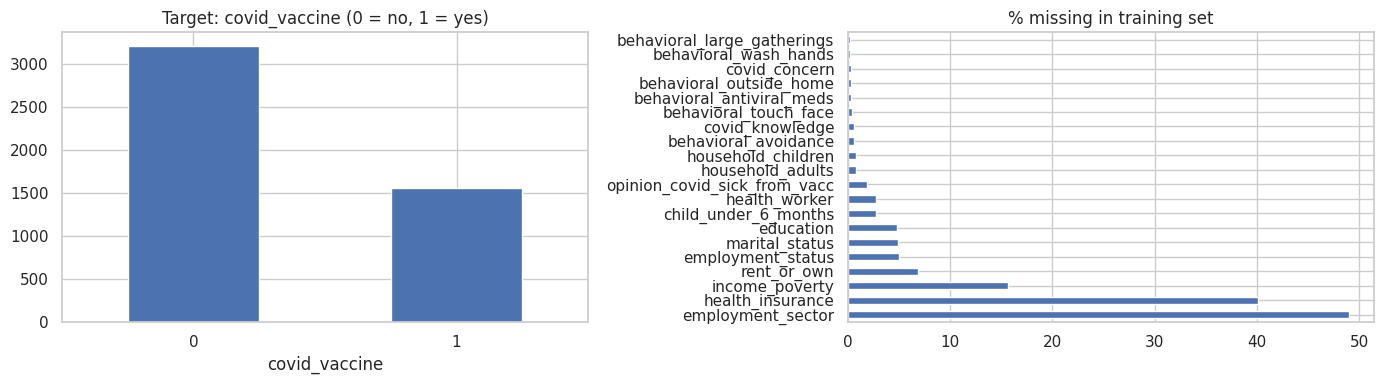

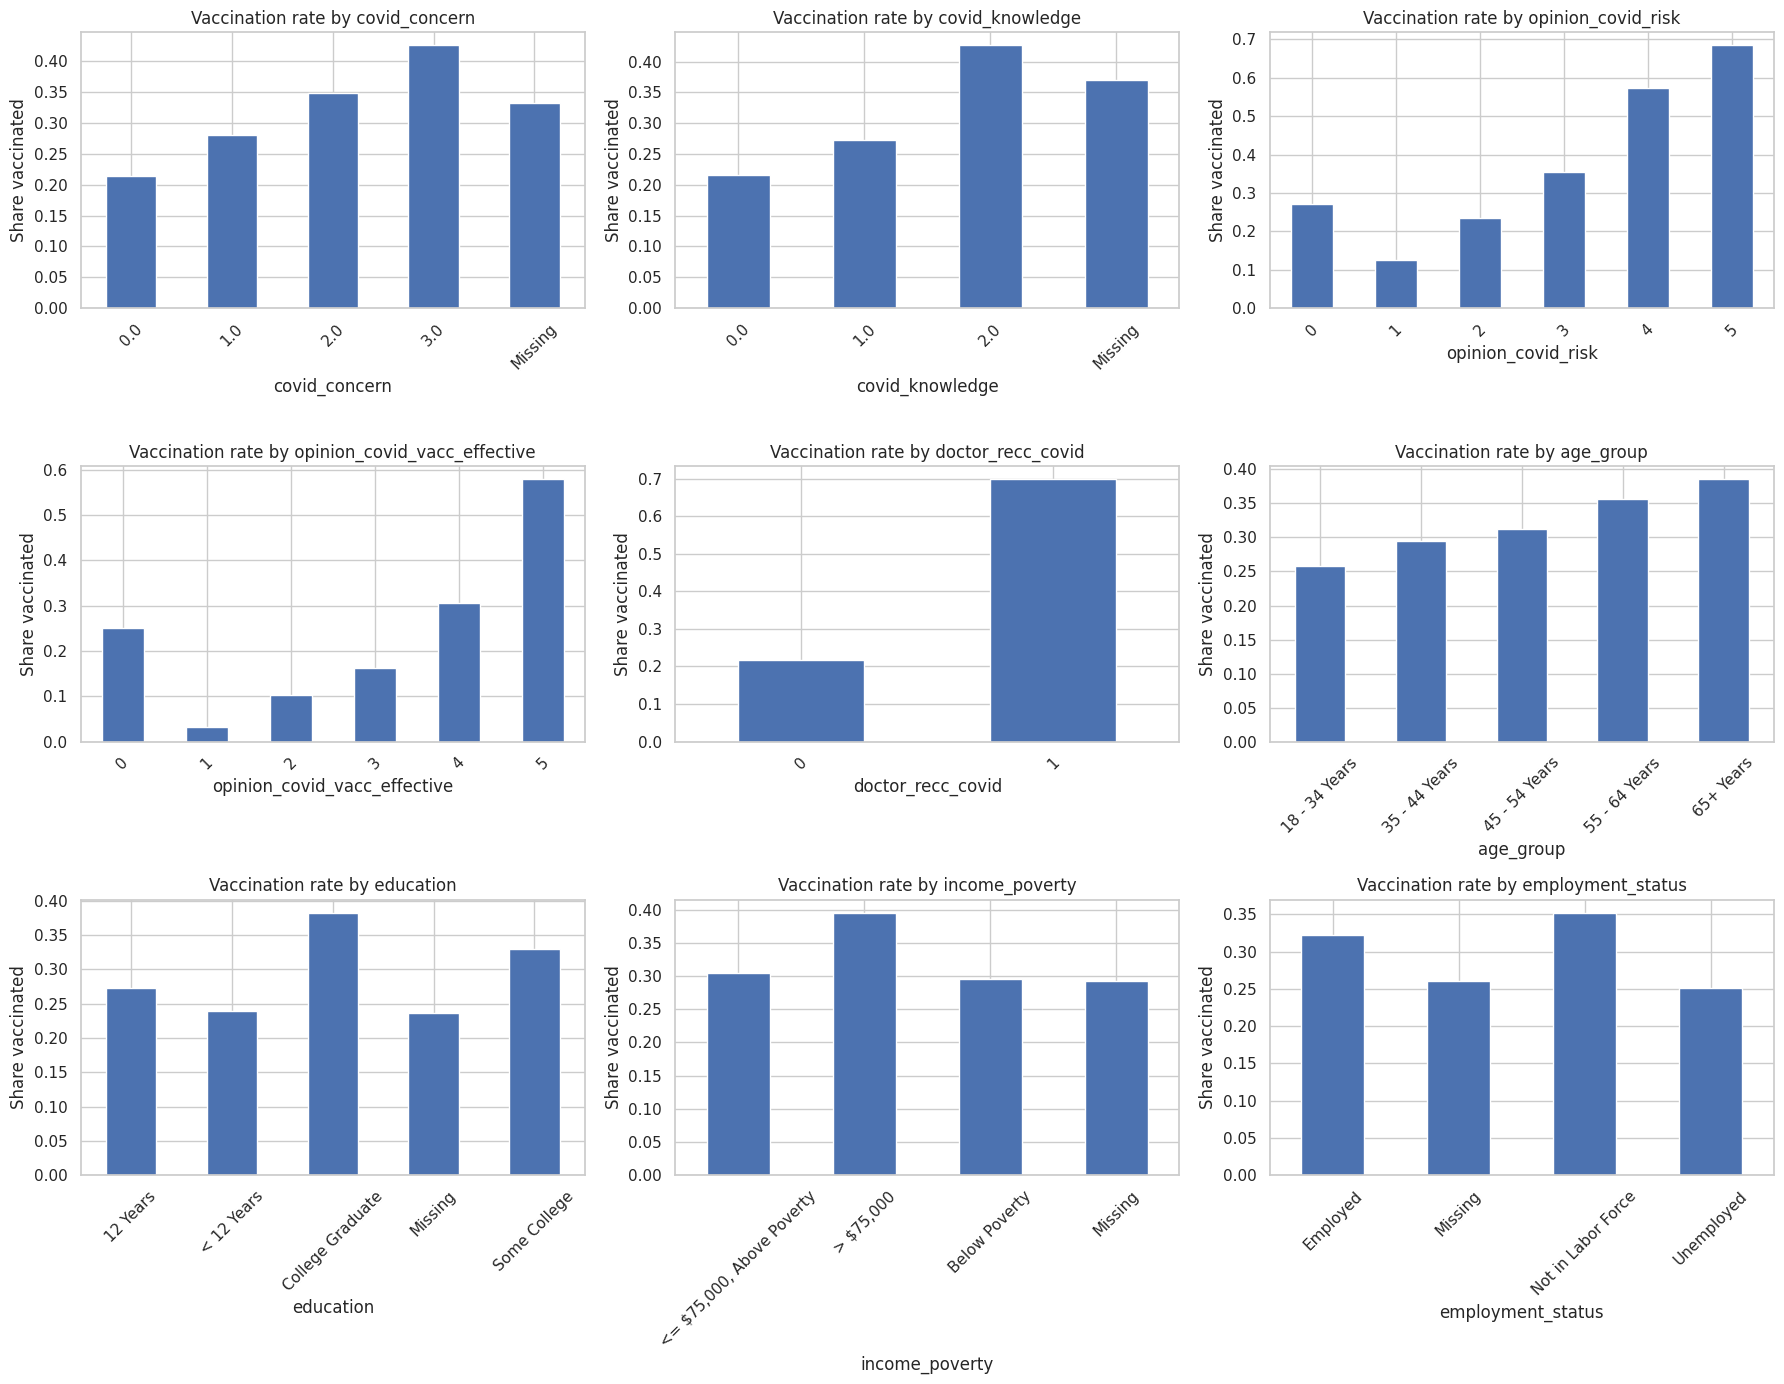

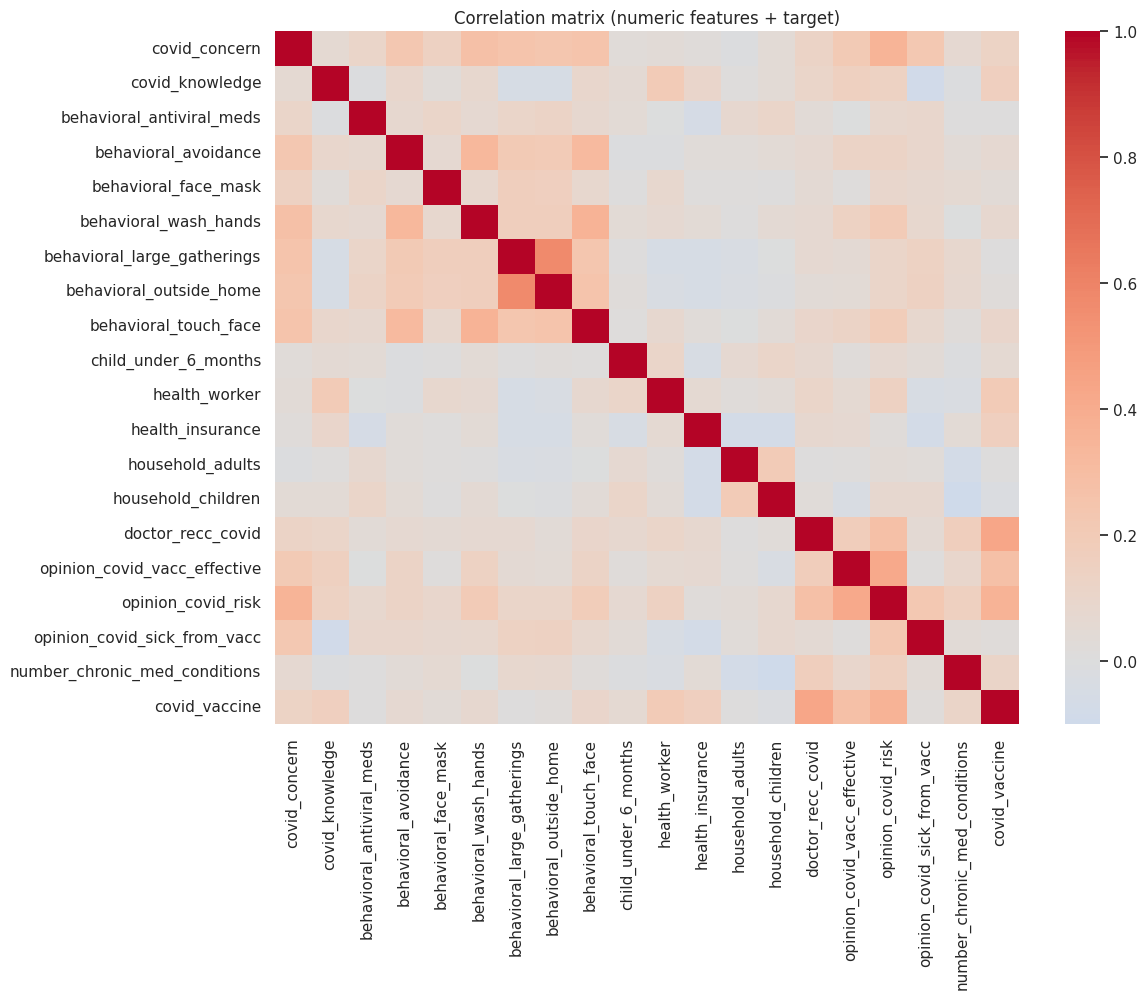

Correlation with target:
doctor_recc_covid                0.430
opinion_covid_risk               0.365
opinion_covid_vacc_effective     0.277
health_worker                    0.197
health_insurance                 0.165
covid_knowledge                  0.164
covid_concern                    0.135
number_chronic_med_conditions    0.115
behavioral_touch_face            0.097
behavioral_wash_hands            0.075
behavioral_avoidance             0.068
child_under_6_months             0.062
behavioral_face_mask             0.037
household_children              -0.022
opinion_covid_sick_from_vacc     0.019
behavioral_outside_home          0.017
behavioral_antiviral_meds        0.011
behavioral_large_gatherings      0.009
household_adults                 0.003
Name: covid_vaccine, dtype: float64


In [72]:
# ============================================================
# 2. LOAD DATA AND EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
print("Train shape:", train.shape, "| Test shape:", test.shape)
print(train.head(), "\n")
print(train.dtypes.value_counts(), "\n")

# --- Target balance ---
print("Target distribution (train):")
print(train[TARGET].value_counts(normalize=True).round(3), "\n")

# --- Missing values in train vs test ---
missing = pd.DataFrame({
    "train_missing_%": train.isna().mean() * 100,
    "test_missing_%": test.isna().mean() * 100,
}).round(1).sort_values("train_missing_%", ascending=False)
print(missing[missing["train_missing_%"] > 0], "\n")

# --- Feature groups (ID and target excluded) ---
FEATURES = [c for c in train.columns if c not in (ID_COL, TARGET)]
CATEGORICAL = ["age_group", "education", "race", "sex", "income_poverty",
               "marital_status", "rent_or_own", "employment_status",
               "census_msa", "employment_sector"]
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]
assert set(FEATURES) == set(test.columns) - {ID_COL}, "Train/test feature mismatch"

# --- Plot 1: target balance and missingness ---
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
train[TARGET].value_counts().sort_index().plot.bar(
    ax=ax[0], title="Target: covid_vaccine (0 = no, 1 = yes)", rot=0)
miss_plot = missing[missing["train_missing_%"] > 0]["train_missing_%"]
miss_plot.plot.barh(ax=ax[1], title="% missing in training set")
plt.tight_layout()
plt.show()

# --- Plot 2: vaccination rate by key groups ---
groups = ["covid_concern", "covid_knowledge", "opinion_covid_risk",
          "opinion_covid_vacc_effective", "doctor_recc_covid", "age_group",
          "education", "income_poverty", "employment_status"]
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.ravel(), groups):
    key = train[col].fillna("Missing").astype(str)
    rate = train.groupby(key)[TARGET].mean().sort_index()
    rate.plot.bar(ax=ax, title=f"Vaccination rate by {col}", rot=45)
    ax.set_ylabel("Share vaccinated")
plt.tight_layout()
plt.show()

# --- Plot 3: correlation of numeric features with the target ---
corr = train[NUMERIC + [TARGET]].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation matrix (numeric features + target)")
plt.show()
print("Correlation with target:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3))

# ============================================================
# 3. EVALUATION METRIC: EXPECTED COST PER RESPONDENT
# ============================================================
# Positive class (1) = vaccinated. Predicting 1 means "no outreach needed".
# Predicting 0 means "target with outreach".

def total_cost(y_true, y_pred):
    """Total money lost given true labels and predicted labels."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    missed = np.sum((y_true == 0) & (y_pred == 1))  # predicted vaccinated, not vaccinated
    wasted = np.sum((y_true == 1) & (y_pred == 0))  # predicted not vaccinated, vaccinated
    return missed * COST_MISSED_UNVACCINATED + wasted * COST_WASTED_VACCINATED

def cost_per_person(y_true, proba, threshold):
    """Average cost per respondent when predicting 1 if proba >= threshold."""
    y_pred = (np.asarray(proba) >= threshold).astype(int)
    return total_cost(y_true, y_pred) / len(y_true)

# Theoretical threshold for calibrated probabilities: predict 1 when p > 41000/42500
THEORETICAL_THRESHOLD = COST_MISSED_UNVACCINATED / (COST_MISSED_UNVACCINATED + COST_WASTED_VACCINATED)
print(f"Theoretical threshold: {THEORETICAL_THRESHOLD:.4f}")

THRESHOLDS = np.round(np.arange(0.50, 1.0001, 0.005), 4)

def best_threshold(y_true, proba):
    """Threshold that minimises expected cost on the given predictions."""
    costs = [cost_per_person(y_true, proba, t) for t in THRESHOLDS]
    i = int(np.argmin(costs))
    return THRESHOLDS[i], costs[i]

# Baselines: what does doing nothing (or always intervening) cost?
X = train[FEATURES]
y = train[TARGET].astype(int)
print("Cost/person, predict everyone 0 (intervene all):", round(total_cost(y, np.zeros(len(y))) / len(y), 2))
print("Cost/person, predict everyone 1 (intervene none):", round(total_cost(y, np.ones(len(y))) / len(y), 2))

In [73]:
# ============================================================
# 3. EVALUATION METRIC: EXPECTED COST PER RESPONDENT
# ============================================================
# Positive class (1) = vaccinated. Predicting 1 means "no outreach needed".
# Predicting 0 means "target with outreach".

def total_cost(y_true, y_pred):
    """Total money lost given true labels and predicted labels."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    missed = np.sum((y_true == 0) & (y_pred == 1))  # predicted vaccinated, not vaccinated
    wasted = np.sum((y_true == 1) & (y_pred == 0))  # predicted not vaccinated, vaccinated
    return missed * COST_MISSED_UNVACCINATED + wasted * COST_WASTED_VACCINATED

def cost_per_person(y_true, proba, threshold):
    """Average cost per respondent when predicting 1 if proba >= threshold."""
    y_pred = (np.asarray(proba) >= threshold).astype(int)
    return total_cost(y_true, y_pred) / len(y_true)

# Theoretical threshold for calibrated probabilities: predict 1 when p > 41000/42500
THEORETICAL_THRESHOLD = COST_MISSED_UNVACCINATED / (COST_MISSED_UNVACCINATED + COST_WASTED_VACCINATED)
print(f"Theoretical threshold: {THEORETICAL_THRESHOLD:.4f}")

THRESHOLDS = np.round(np.arange(0.50, 1.0001, 0.005), 4)

def best_threshold(y_true, proba):
    """Threshold that minimises expected cost on the given predictions."""
    costs = [cost_per_person(y_true, proba, t) for t in THRESHOLDS]
    i = int(np.argmin(costs))
    return THRESHOLDS[i], costs[i]

# Baselines: what does doing nothing (or always intervening) cost?
X = train[FEATURES]
y = train[TARGET].astype(int)
print("Cost/person, predict everyone 0 (intervene all):", round(total_cost(y, np.zeros(len(y))) / len(y), 2))
print("Cost/person, predict everyone 1 (intervene none):", round(total_cost(y, np.ones(len(y))) / len(y), 2))

# ============================================================
# FINAL SUBMISSION GENERATION (Using ensemble_avg with threshold 0.955)
# ============================================================
import os
if 'test_proba' in globals() and 'ensemble_avg' in test_proba:
    SUB_TEMPLATE_PATH = "/content/dataset_C_example_submission.csv"
    if os.path.exists(SUB_TEMPLATE_PATH):
        template_df = pd.read_csv(SUB_TEMPLATE_PATH)
        final_predictions = (test_proba["ensemble_avg"] >= 0.955).astype(int)
        submission_df = pd.DataFrame({
            ID_COL: test[ID_COL],
            TARGET: final_predictions
        })
        submission_df = submission_df[template_df.columns]
        submission_df.to_csv(SUB_TEMPLATE_PATH, index=False)
        print(f"\n[Final Submission] Successfully written to {SUB_TEMPLATE_PATH}")
        print(f"[Final Submission] Predicted vaccinated share: {final_predictions.mean():.4%}")
    else:
        print("\n[Warning] Submission template path not found.")


Theoretical threshold: 0.9647
Cost/person, predict everyone 0 (intervene all): 490.12
Cost/person, predict everyone 1 (intervene none): 27603.45

[Final Submission] Successfully written to /content/dataset_C_example_submission.csv
[Final Submission] Predicted vaccinated share: 0.0632%


In [74]:
import os
import pandas as pd
from google.colab import files

# Define paths
sub_template = '/content/submissions/3_ensemble_avg.csv'
target_path = '/content/dataset_C_example_submission.csv'

# Ensure the ensemble predictions exist
if os.path.exists(sub_template):
    # Copy the optimal ensemble prediction over to the expected final destination
    df_final = pd.read_csv(sub_template)
    df_final.to_csv(target_path, index=False)
    print(f"[Success] Prepared final submission at {target_path} (Rows: {len(df_final)})")

    # Trigger download
    files.download(target_path)
else:
    print(f"[Error] Could not find the predicted ensemble at {sub_template}. Please rerun cell 7sNLOSNmjFHC first.")

[Success] Prepared final submission at /content/dataset_C_example_submission.csv (Rows: 4749)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [75]:
import pandas as pd

# Read the generated final submission
sub_df = pd.read_csv('/content/dataset_C_example_submission.csv')
print(f"Total Rows: {len(sub_df)}")
print("\nFirst 10 rows of the submission:")
display(sub_df.head(10))

# Print class distribution counts
print("\nPredicted class distribution:")
print(sub_df['covid_vaccine'].value_counts())

Total Rows: 4749

First 10 rows of the submission:


,respondent_id,covid_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0
5,4762,0
6,4763,0
7,4764,0
8,4765,0
9,4766,0



Predicted class distribution:
covid_vaccine
0    4746
1       3
Name: count, dtype: int64


Step 4: Dataset Splitting and Preprocessing Pipelines

In [76]:
# ============================================================
# 4. TRAIN / HOLD-OUT SPLIT AND PRE-PROCESSING
# ============================================================
X_tr, X_ho, y_tr, y_ho = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Training rows:", len(X_tr), "| Hold-out rows:", len(X_ho))

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

def make_preprocessor(scale_numeric):
    """
    Numeric: median imputation + a flag for each feature that had missing values
             (missingness itself can be informative, e.g. income not reported).
    Categorical: missing becomes its own "Missing" category, then one-hot encoding.
    """
    num_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale_numeric:
        num_steps.append(("scale", StandardScaler()))
    cat_steps = [
        ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
    return ColumnTransformer([
        ("num", Pipeline(num_steps), NUMERIC),
        ("cat", Pipeline(cat_steps), CATEGORICAL),
    ])

def make_pipeline(model, scale):
    return Pipeline([("prep", make_preprocessor(scale)), ("clf", model)])

Training rows: 3804 | Hold-out rows: 952


Step 5: Machine Learning Models and Hyperparameter Tuning

In [ ]:
# ============================================================
# 5. MODELS AND HYPER-PARAMETER TUNING
# ============================================================
# Tuning uses log-loss: it rewards well-calibrated probabilities, which the
# threshold step below depends on. The cost metric is used afterwards.
SEARCH_SPACES = {
    "logistic_regression": (
        make_pipeline(LogisticRegression(max_iter=3000), scale=True),
        {"clf__C": np.logspace(-3, 2, 20)},
    ),
    "random_forest": (
        make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), scale=False),
        {"clf__n_estimators": [300, 600],
         "clf__max_depth": [3, 5, 8, None],
         "clf__min_samples_leaf": [10, 20, 40, 80],
         "clf__max_features": ["sqrt", 0.3, 0.5]},
    ),
    "hist_gradient_boosting": (
        make_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scale=False),
        {"clf__learning_rate": [0.01, 0.03, 0.1],
         "clf__max_depth": [2, 3, 4, None],
         "clf__min_samples_leaf": [20, 50, 100],
         "clf__l2_regularization": [0.0, 1.0, 5.0]},
    ),
}

tuned = {}
for name, (pipe, grid) in SEARCH_SPACES.items():
    search = RandomizedSearchCV(
        pipe, grid, n_iter=N_SEARCH_ITER, scoring="neg_log_loss",
        cv=cv, random_state=RANDOM_STATE, n_jobs=-1, refit=True)
    search.fit(X_tr, y_tr)
    tuned[name] = search.best_estimator_
    params = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
    print(f"{name}: CV log-loss = {-search.best_score_:.4f} | best params = {params}")

# Untuned baseline for comparison (no hyper-parameter search)
tuned["baseline_logistic_default"] = make_pipeline(LogisticRegression(max_iter=3000), scale=True)

logistic_regression: CV log-loss = 0.4298 | best params = {'C': np.float64(0.12742749857031335)}


Step 6: Out-of-Fold (OOF) Performance Analysis

In [ ]:
# ============================================================
# 6. CROSS-VALIDATED PERFORMANCE (out-of-fold predictions)
# ============================================================
# Each training row is predicted by a model that never saw it.
oof = {}
for name, est in tuned.items():
    oof[name] = cross_val_predict(est, X_tr, y_tr, cv=cv,
                                  method="predict_proba", n_jobs=-1)[:, 1]

# Ensemble: average the probabilities of the three tuned models
MAIN_MODELS = ["logistic_regression", "random_forest", "hist_gradient_boosting"]
oof["ensemble_avg"] = np.mean([oof[m] for m in MAIN_MODELS], axis=0)

def fold_costs(proba, threshold):
    """Cost per respondent in each CV fold, to measure random variation."""
    y_arr = np.asarray(y_tr)
    return np.array([cost_per_person(y_arr[va], proba[va], threshold)
                     for _, va in cv.split(X_tr, y_tr)])

rows = []
for name, p in oof.items():
    t, c = best_threshold(y_tr, p)
    fc = fold_costs(p, t)
    rows.append({
        "model": name,
        "threshold": t,
        "CV_cost_per_person": round(c, 2),
        "fold_cost_std": round(fc.std(), 2),
        "CV_logloss": round(log_loss(y_tr, p), 4),
        "CV_AUC": round(roc_auc_score(y_tr, p), 4),
    })
cv_summary = pd.DataFrame(rows).sort_values("CV_cost_per_person").reset_index(drop=True)
print("\n=== Cross-validation summary (ranked by cost, best first) ===")
print(cv_summary.to_string())

# Plot the cost curve for the best model
best_name = cv_summary.loc[0, "model"]
curve = [cost_per_person(y_tr, oof[best_name], t) for t in THRESHOLDS]
plt.figure(figsize=(8, 4))
plt.plot(THRESHOLDS, curve, label=best_name)
plt.axvline(THEORETICAL_THRESHOLD, ls="--", color="red", label="theoretical threshold")
plt.xlabel("Decision threshold")
plt.ylabel("Expected cost per respondent ($)")
plt.title("Cost vs threshold (out-of-fold)")
plt.legend()
plt.show()

Step 7: Hold-out Validation on Unseen Data

Above Cell

In [ ]:
# ============================================================
# 7. HOLD-OUT CHECK ON UNSEEN DATA
# ============================================================
holdout = {}
for name, est in tuned.items():
    est.fit(X_tr, y_tr)
    holdout[name] = est.predict_proba(X_ho)[:, 1]
holdout["ensemble_avg"] = np.mean([holdout[m] for m in MAIN_MODELS], axis=0)

thr = dict(zip(cv_summary["model"], cv_summary["threshold"]))
ho_rows = []
for name in cv_summary["model"]:
    p = holdout[name]
    ho_rows.append({
        "model": name,
        "holdout_cost_per_person": round(cost_per_person(y_ho, p, thr[name]), 2),
        "holdout_logloss": round(log_loss(y_ho, p), 4),
        "holdout_AUC": round(roc_auc_score(y_ho, p), 4),
    })
holdout_summary = pd.DataFrame(ho_rows)
final_table = cv_summary.merge(holdout_summary, on="model")
print("\n=== CV vs hold-out ===")
print(final_table.to_string())

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Set up plot
plt.figure(figsize=(10, 7))

# Calculate and plot ROC for each model on Hold-out Set
for name in ['logistic_regression', 'random_forest', 'hist_gradient_boosting', 'ensemble_avg']:
    fpr, tpr, _ = roc_curve(y_ho, holdout[name])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) - Hold-out Set', fontsize=14, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Print final comparative table sorted by holdout cost
print("=== Model Performance Comparison Table ===")
comparison_df = final_table[['model', 'threshold', 'CV_cost_per_person', 'holdout_cost_per_person', 'CV_logloss', 'holdout_logloss', 'CV_AUC', 'holdout_AUC']]
display(comparison_df.sort_values(by='holdout_cost_per_person'))

Step 8: Refitting on All Data and Creating Test Submissions

In [ ]:
# ============================================================
# 8. REFIT ON ALL TRAINING DATA AND PREDICT THE TEST SET
# ============================================================
X_test = test[FEATURES]
test_proba = {}
for name in tuned:
    model = clone(tuned[name]).fit(X, y)   # X, y = full training set
    test_proba[name] = model.predict_proba(X_test)[:, 1]
test_proba["ensemble_avg"] = np.mean([test_proba[m] for m in MAIN_MODELS], axis=0)

# Keep the 5 best models by CV cost, ordered best to worst
top5 = cv_summary["model"].tolist()[:5]
os.makedirs("submissions", exist_ok=True)
for rank, name in enumerate(top5, start=1):
    pred = (test_proba[name] >= thr[name]).astype(int)
    sub = pd.DataFrame({ID_COL: test[ID_COL], TARGET: pred})
    path = f"submissions/{rank}_{name}.csv"
    sub.to_csv(path, index=False)
    print(f"Saved {path}  rows={len(sub)}  predicted vaccinated share={pred.mean():.3f}")

# Also save probabilities for the team's records
pd.DataFrame({ID_COL: test[ID_COL], **{k: v for k, v in test_proba.items()}}).to_csv(
    "submissions/all_test_probabilities.csv", index=False)
print("\nCheck the required submission format on Canvas before uploading.")

Step 9: Feature Importance Comparison Across Ensemble Models



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance

# 1. Extract Preprocessing and Feature Names
preprocessor = tuned["logistic_regression"].named_steps["prep"]
ohe_cols = list(preprocessor.named_transformers_["cat"].named_steps["onehot"].get_feature_names_out(CATEGORICAL))
num_imputer = preprocessor.named_transformers_["num"].named_steps["impute"]
num_missing_cols = [f"{col}_is_missing" for idx, col in enumerate(NUMERIC) if idx in num_imputer.indicator_.features_]
all_features = NUMERIC + num_missing_cols + ohe_cols

# 2. Extract Feature Importances
# A. Logistic Regression Coefficients
logreg_model = tuned["logistic_regression"].named_steps["clf"]
logreg_importances = np.abs(logreg_model.coef_[0])
logreg_df = pd.DataFrame({"Feature": all_features, "Importance": logreg_importances}).sort_values(by="Importance", ascending=False).head(10)

# B. Random Forest Feature Importances
rf_model = tuned["random_forest"].named_steps["clf"]
rf_importances = rf_model.feature_importances_
rf_df = pd.DataFrame({"Feature": all_features, "Importance": rf_importances}).sort_values(by="Importance", ascending=False).head(10)

# C. Hist Gradient Boosting (using Permutation Importance on Hold-out Set to evaluate raw features)
hgb_pipeline = tuned["hist_gradient_boosting"]
perm_importance = permutation_importance(hgb_pipeline, X_ho, y_ho, n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
hgb_df = pd.DataFrame({"Feature": FEATURES, "Importance": perm_importance.importances_mean}).sort_values(by="Importance", ascending=False).head(10)

# 3. Plotting the Importances Side-by-Side
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

sns.barplot(data=logreg_df, x="Importance", y="Feature", ax=axes[0], hue="Feature", palette="Blues_r", legend=False)
axes[0].set_title("Logistic Regression\n(Top 10 Absolute Coefficients)", fontsize=12)
axes[0].set_xlabel("Absolute Coefficient Value")
axes[0].set_ylabel("Feature")

sns.barplot(data=rf_df, x="Importance", y="Feature", ax=axes[1], hue="Feature", palette="Oranges_r", legend=False)
axes[1].set_title("Random Forest\n(Top 10 Feature Importances - MDI)", fontsize=12)
axes[1].set_xlabel("Mean Decrease in Impurity (MDI)")
axes[1].set_ylabel("")

sns.barplot(data=hgb_df, x="Importance", y="Feature", ax=axes[2], hue="Feature", palette="Greens_r", legend=False)
axes[2].set_title("Hist Gradient Boosting\n(Top 10 Permutation Importances on Hold-out)", fontsize=12)
axes[2].set_xlabel("Drop in Log-Loss metric")
axes[2].set_ylabel("")

plt.suptitle("Feature Importance Comparison Across Models", fontsize=16, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()